# Użycie "twarzy własnych" (eigenfaces)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import os
import scipy.io
plt.rcParams['figure.figsize'] = [8, 8]
plt.rcParams.update({'font.size': 18})

mat_contents = scipy.io.loadmat(os.path.join('..','..','MK_databook_python-master','DATA','allFaces.mat'))
faces = mat_contents['faces']
m = int(mat_contents['m'])
n = int(mat_contents['n'])
nfaces = np.ndarray.flatten(mat_contents['nfaces'])

# We use the first 36 people for training data
trainingFaces = faces[:,:np.sum(nfaces[:36])]
avgFace = np.mean(trainingFaces,axis=1) # size n*m by 1

# Compute eigenfaces on mean-subtracted training data
X = trainingFaces - np.tile(avgFace,(trainingFaces.shape[1],1)).T
U, S, VT = np.linalg.svd(X,full_matrices=0)

/tmp/ipykernel_1566267/3241645571.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  m = int(mat_contents['m'])
/tmp/ipykernel_1566267/3241645571.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  n = int(mat_contents['n'])


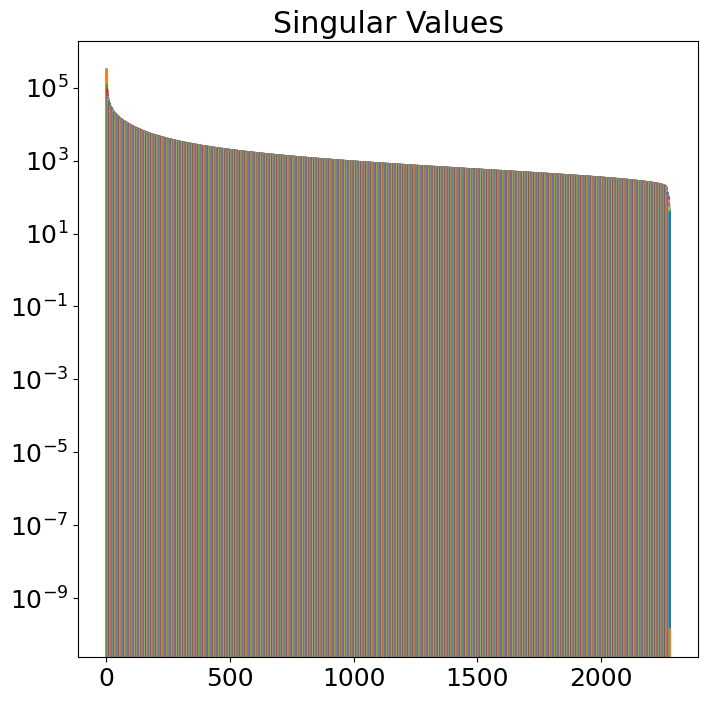

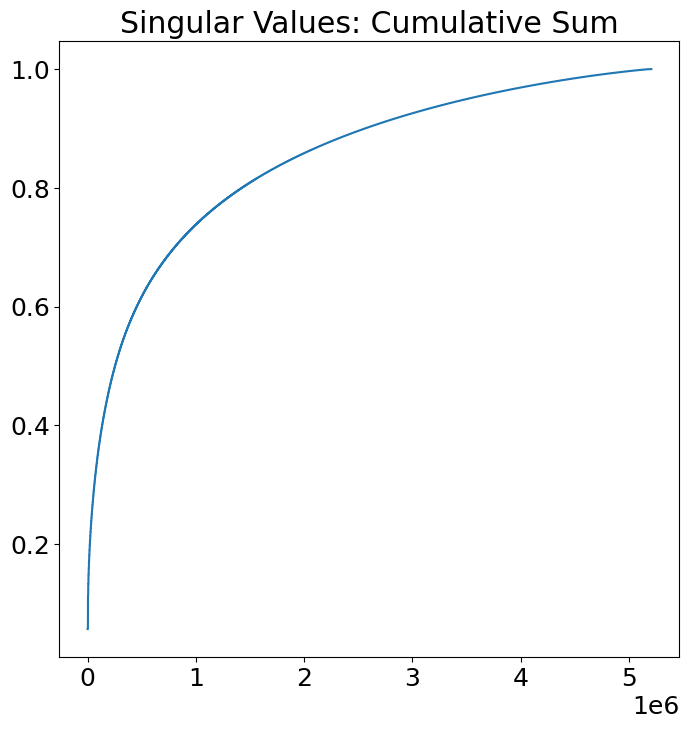

In [3]:
# Plot singular values

plt.figure(1)
plt.semilogy(np.diag(S))
plt.title('Singular Values')
plt.show()

plt.figure(2)
plt.plot(np.cumsum(np.diag(S))/np.sum(np.diag(S)))
plt.title('Singular Values: Cumulative Sum')
plt.show()

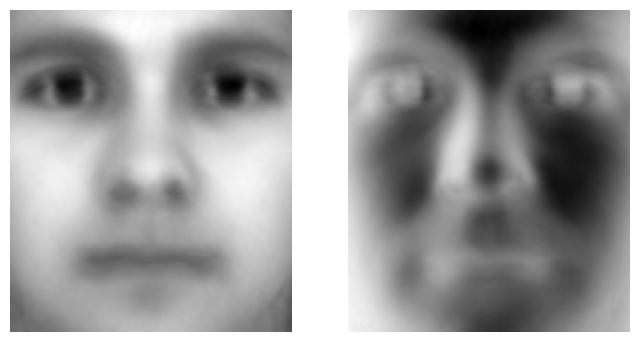

In [4]:
# two more faces

fig1 = plt.figure()
ax1 = fig1.add_subplot(121)
img_avg = ax1.imshow(np.reshape(avgFace,(m,n)).T)
img_avg.set_cmap('gray')
plt.axis('off')

ax2 = fig1.add_subplot(122)
img_u1 = ax2.imshow(np.reshape(U[:,0],(m,n)).T)
img_u1.set_cmap('gray')
plt.axis('off')

plt.show()

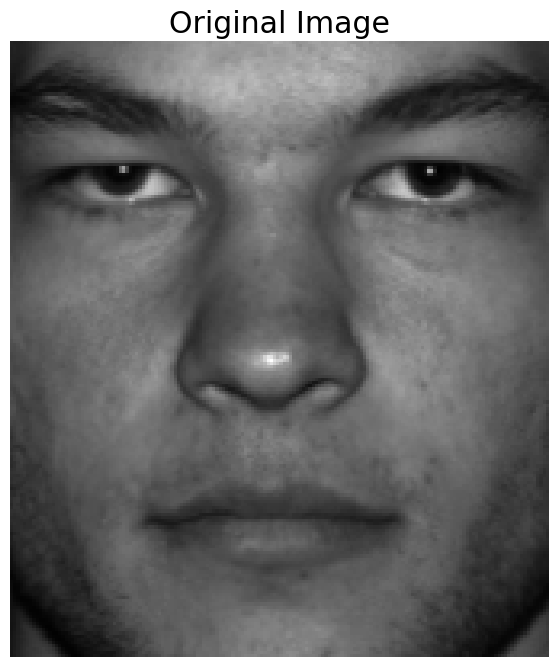

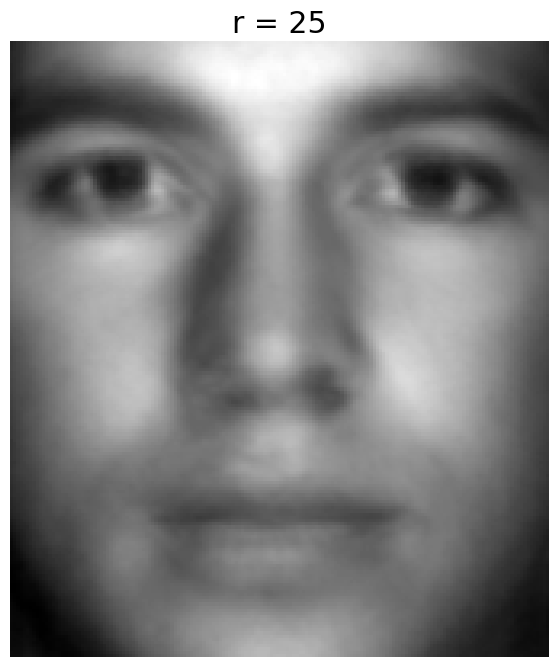

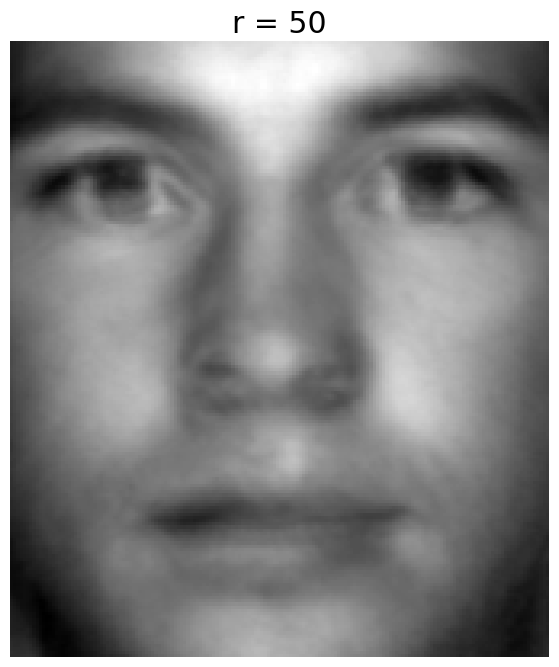

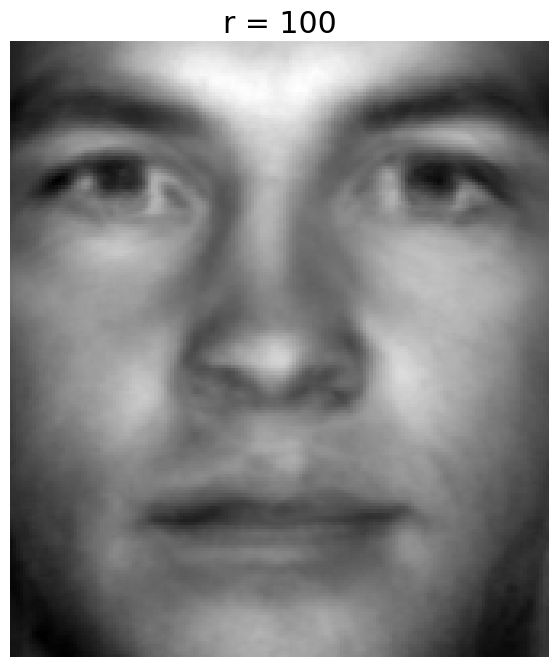

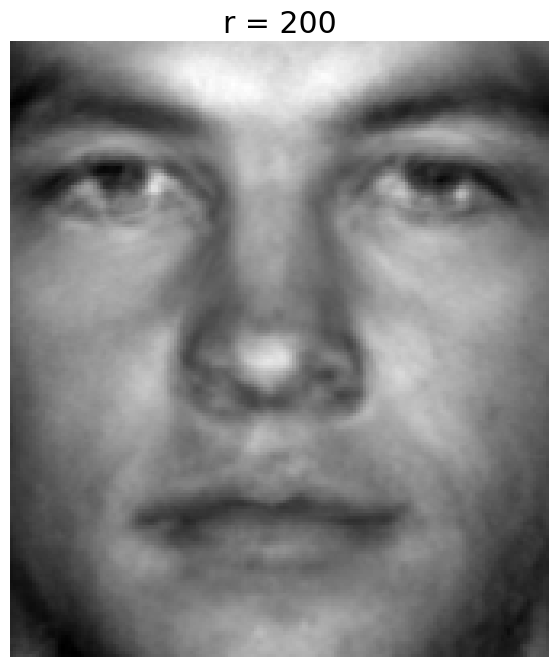

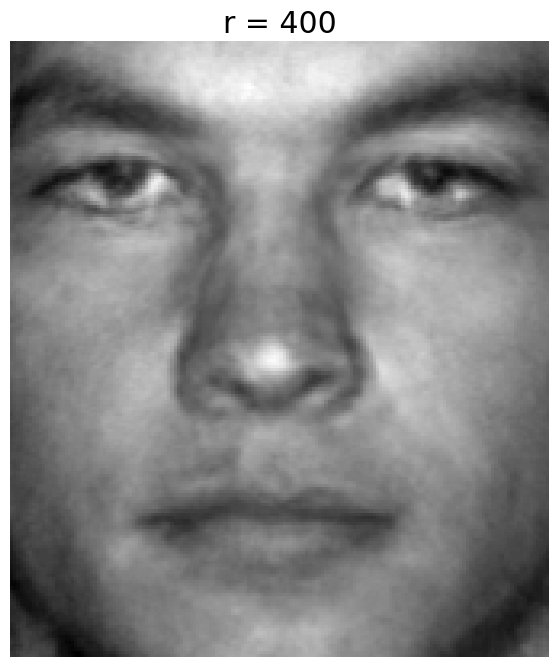

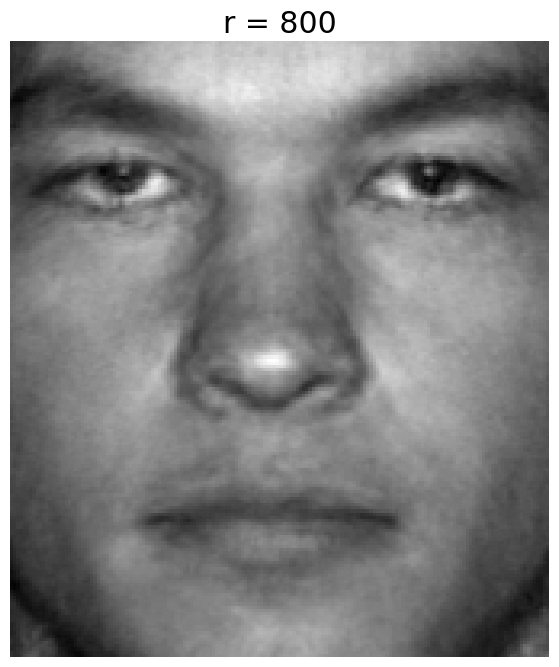

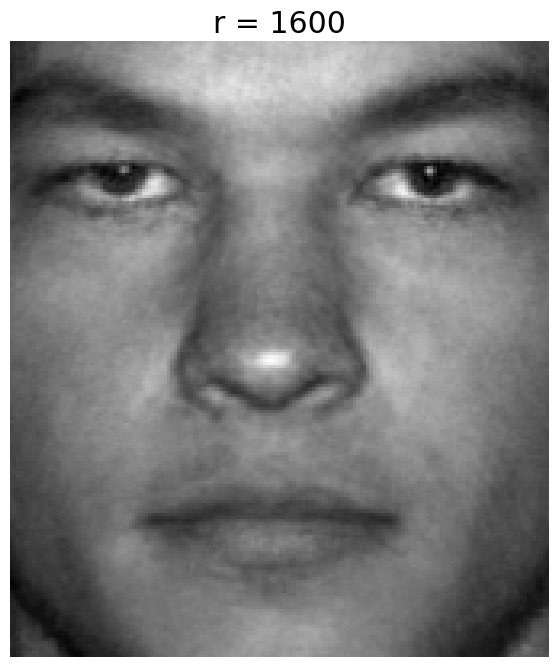

In [5]:
## Now show eigenface reconstruction of image that was omitted from test set

testFace = faces[:,np.sum(nfaces[:36])] # First face of person 37
plt.imshow(np.reshape(testFace,(m,n)).T)
plt.set_cmap('gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

testFaceMS = testFace - avgFace
r_list = [25, 50, 100, 200, 400, 800, 1600]

for r in r_list:
    reconFace = avgFace + U[:,:r]  @ U[:,:r].T @ testFaceMS
    img = plt.imshow(np.reshape(reconFace,(m,n)).T)
    img.set_cmap('gray')
    plt.title('r = ' + str(r))
    plt.axis('off')
    plt.show()

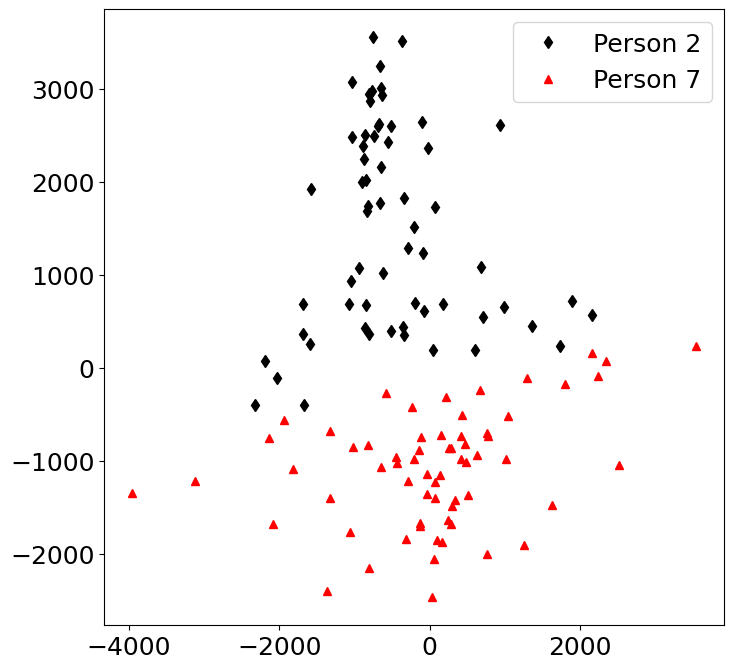

In [6]:
## Project person 2 and 7 onto PC5 and PC6

P1num = 2 # Person number 2
P2num = 7 # Person number 7

P1 = faces[:,np.sum(nfaces[:(P1num-1)]):np.sum(nfaces[:P1num])]
P2 = faces[:,np.sum(nfaces[:(P2num-1)]):np.sum(nfaces[:P2num])]

P1 = P1 - np.tile(avgFace,(P1.shape[1],1)).T
P2 = P2 - np.tile(avgFace,(P2.shape[1],1)).T

PCAmodes = [5, 6] # Project onto PCA modes 5 and 6
PCACoordsP1 = U[:,PCAmodes-np.ones_like(PCAmodes)].T @ P1
PCACoordsP2 = U[:,PCAmodes-np.ones_like(PCAmodes)].T @ P2

plt.plot(PCACoordsP1[0,:],PCACoordsP1[1,:],'d',color='k',label='Person 2')
plt.plot(PCACoordsP2[0,:],PCACoordsP2[1,:],'^',color='r',label='Person 7')

plt.legend()
plt.show()

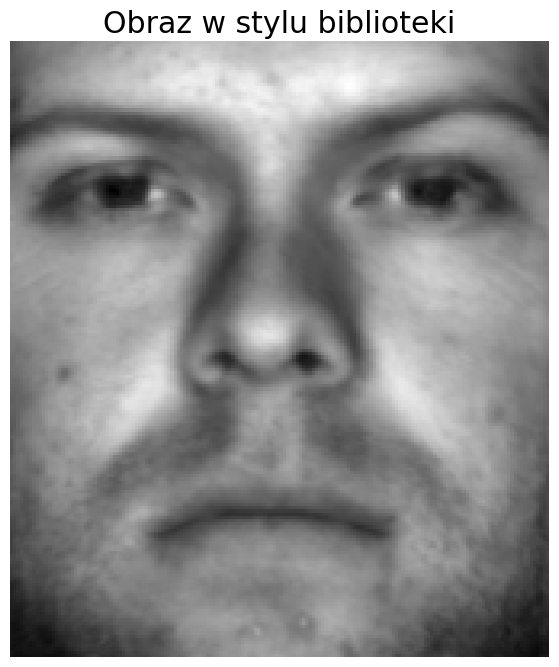

In [7]:
# 1. Styl = SVD na wybranej bazie
faces_style = faces   # albo trainingFaces, jeśli chcesz styl tylko z części

avgFace_style = np.mean(faces_style, axis=1, keepdims=True)
X_style = faces_style - avgFace_style

U_style, S_style, VT_style = np.linalg.svd(X_style, full_matrices=False)

# 2. Nowy obraz (tu: po prostu pierwsza twarz z bazy)
newFace = faces[:, 0]    # używasz dowolnej twarzy do testów

# 3. Mean-subtraction względem średniej biblioteki stylu
newMS = newFace - avgFace_style[:, 0]

# 4. Projekcja na podprzestrzeń stylu
r = 100
Ur = U_style[:, :r]
coeffs = Ur.T @ newMS

# 5. Rekonstrukcja "w stylu"
recon_style = avgFace_style[:, 0] + Ur @ coeffs

# 6. Wyświetlenie
plt.imshow(recon_style.reshape(m, n).T, cmap='gray')
plt.title("Obraz w stylu biblioteki")
plt.axis('off')
plt.show()


/tmp/ipykernel_1566267/3900474122.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  m = int(mat['m'])         # liczba wierszy obrazka
/tmp/ipykernel_1566267/3900474122.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  n = int(mat['n'])         # liczba kolumn obrazka


Rozmiar macierzy faces: (32256, 2410)
Rozmiar U_style: (32256, 2410)


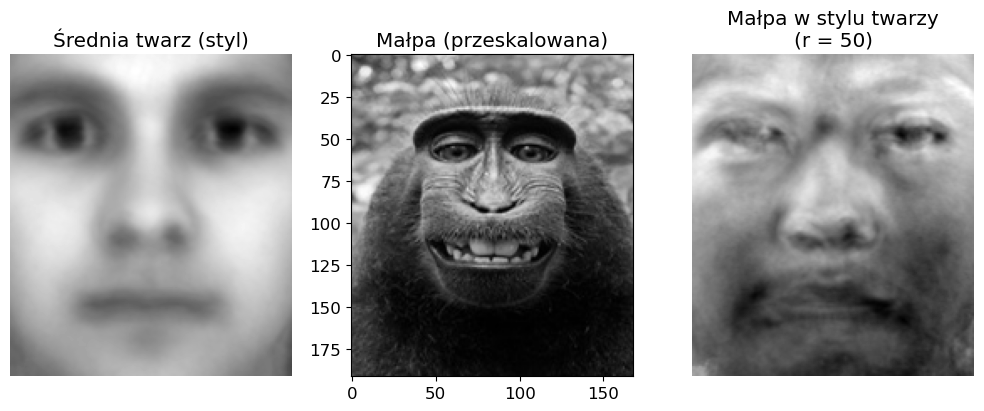

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io
import os
import requests
from io import BytesIO
from PIL import Image

plt.rcParams['figure.figsize'] = [10, 5]
plt.rcParams.update({'font.size': 12})

# -------------------------------------------------------------
# 1. Wczytanie bazy twarzy i obliczenie stylu (średnia + U)
# -------------------------------------------------------------
mat_path = os.path.join('..', '..', 'MK_databook_python-master', 'DATA', 'allFaces.mat')
mat = scipy.io.loadmat(mat_path)

faces = mat['faces']      # każda kolumna = jedna twarz (spłaszczona)
m = int(mat['m'])         # liczba wierszy obrazka
n = int(mat['n'])         # liczba kolumn obrazka

print("Rozmiar macierzy faces:", faces.shape)  # (m*n, liczba_twarzy)

# Możemy użyć całej bazy jako "biblioteki stylu"
faces_style = faces

# Średnia twarz stylu
avgFace_style = np.mean(faces_style, axis=1, keepdims=True)

# Mean-subtraction
X_style = faces_style - avgFace_style

# SVD: X = U S V^T
U_style, S_style, VT_style = np.linalg.svd(X_style, full_matrices=False)
print("Rozmiar U_style:", U_style.shape)

# -------------------------------------------------------------
# 2. Funkcja: wczytaj obraz i zamień na wektor
# -------------------------------------------------------------
def load_image_as_vector_from_url(url, m, n):
    """
    Pobiera obraz z danego URL, konwertuje do skali szarości,
    zmienia rozmiar na (m, n), a następnie spłaszcza do wektora (m*n,).
    """
    response = requests.get(url)
    response.raise_for_status()  # zgłosi błąd, jeśli URL jest zły

    img = Image.open(BytesIO(response.content))

    # Skala szarości
    img = img.convert('L')

    # Zmiana rozmiaru na (n szerokość, m wysokość)
    img = img.resize((n, m))

    # Konwersja do tablicy numpy (m, n)
    img_arr = np.array(img, dtype=np.float64)

    # UWAGA: w oryginalnych twarzach jest reshape(...).T,
    # więc robimy transpozycję, żeby zachować ten sam układ.
    img_arr = img_arr.T  # teraz (n, m) -> (m, n) po .T przy wyświetlaniu

    # Spłaszczamy do wektora
    vec = img_arr.reshape(m * n)

    # (opcjonalnie) skalowanie do zakresu jak w faces
    # Sprawdź w swoim środowisku:
    # print(faces.min(), faces.max())
    # Jeśli faces są np. w [0, 1], warto podzielić przez 255:
    # vec = vec / 255.0

    return vec

# -------------------------------------------------------------
# 3. Funkcja: narzuć styl eigenfaces na nowy obraz
# -------------------------------------------------------------
def stylize_face(newFace_vec, avgFace_style, U_style, r):
    """
    newFace_vec: wektor (m*n,)
    avgFace_style: średnia twarz (m*n, 1)
    U_style: macierz eigenfaces (m*n, k)
    r: liczba pierwszych eigenfaces do użycia
    """
    newFace_vec = newFace_vec.reshape(-1)          # na wszelki wypadek
    faceMS = newFace_vec - avgFace_style[:, 0]     # odejmujemy średnią stylu

    Ur = U_style[:, :r]                            # pierwsze r eigenfaces
    coeffs = Ur.T @ faceMS                         # współczynniki projekcji
    recon = avgFace_style[:, 0] + Ur @ coeffs      # rekonstrukcja w stylu

    return recon

# -------------------------------------------------------------
# 4. Przykład użycia: obraz "małpy" z internetu
# -------------------------------------------------------------


# Wczytanie obrazu małpy jako wektora


from PIL import Image
import numpy as np

def load_image_as_vector_from_file(path, m, n):
    img = Image.open(path).convert('L')
    img = img.resize((n, m))
    #img_arr = np.array(img, dtype=np.float64).T
    img_arr = np.array(img, dtype=np.float64)
    return img_arr.reshape(m * n)

monkey_vec = load_image_as_vector_from_file("malpa1.jpg", m, n)


# Stylizacja: projekcja na podprzestrzeń eigenfaces
r = 50  # liczba eigenfaces - możesz eksperymentować: 50, 100, 300...
monkey_styled = stylize_face(monkey_vec, avgFace_style, U_style, r)

# -------------------------------------------------------------
# 5. Wizualizacja: oryginał vs wersja w stylu twarzy
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3)

# 1. Średnia twarz stylu (dla porównania)
axes[0].imshow(avgFace_style.reshape(m, n).T, cmap='gray')
axes[0].set_title("Średnia twarz (styl)")
axes[0].axis('off')

# 2. Oryginalny obraz małpy po przeskalowaniu
axes[1].imshow(monkey_vec.reshape(m, n).T, cmap='gray')
axes[1].set_title("Małpa (przeskalowana)")
axes[1].axis('on')

# 3. Małpa w stylu biblioteki twarzy
axes[2].imshow(monkey_styled.reshape(m, n).T, cmap='gray')
axes[2].set_title(f"Małpa w stylu twarzy\n(r = {r})")
axes[2].axis('off')

plt.tight_layout()
plt.show()


In [21]:
m

168

In [22]:
n

192

Suma wartości singularnych: 5626677.859082583


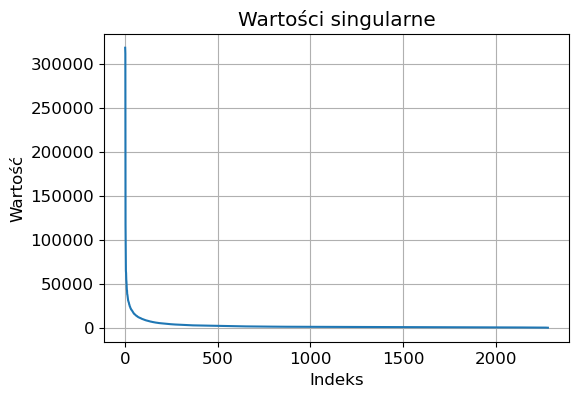

In [43]:
# Suma wartości singularnych
singular_sum = np.sum(S)
print("Suma wartości singularnych:", singular_sum)

# Wykres wartości singularnych
plt.figure(figsize=(6,4))
plt.plot(S)
plt.title("Wartości singularne")
plt.xlabel("Indeks")
plt.ylabel("Wartość")
plt.grid(True)
plt.show()

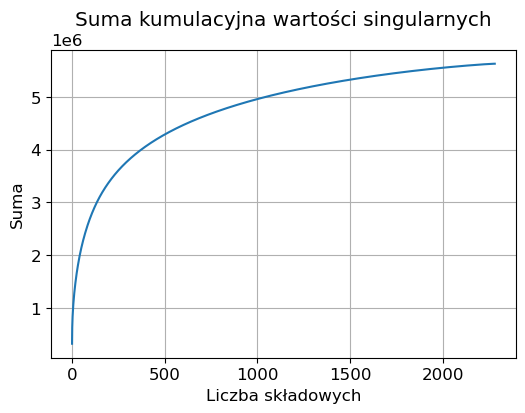

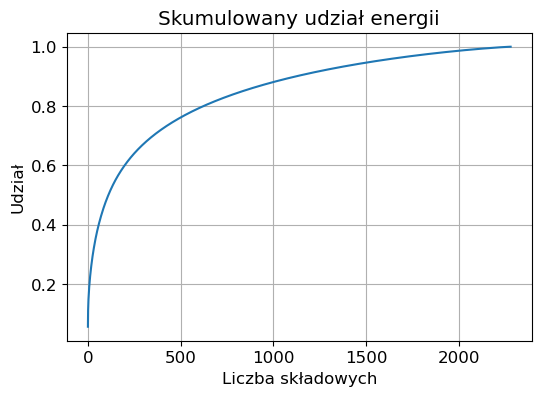

In [44]:
# Suma kumulacyjna
cum_singular = np.cumsum(S)

# Udział skumulowany
cum_share = cum_singular / np.sum(S)

# Wykres sumy kumulacyjnej
plt.figure(figsize=(6,4))
plt.plot(cum_singular)
plt.title("Suma kumulacyjna wartości singularnych")
plt.xlabel("Liczba składowych")
plt.ylabel("Suma")
plt.grid(True)
plt.show()

# Wykres udziału skumulowanego
plt.figure(figsize=(6,4))
plt.plot(cum_share)
plt.title("Skumulowany udział energii")
plt.xlabel("Liczba składowych")
plt.ylabel("Udział")
plt.grid(True)
plt.show()

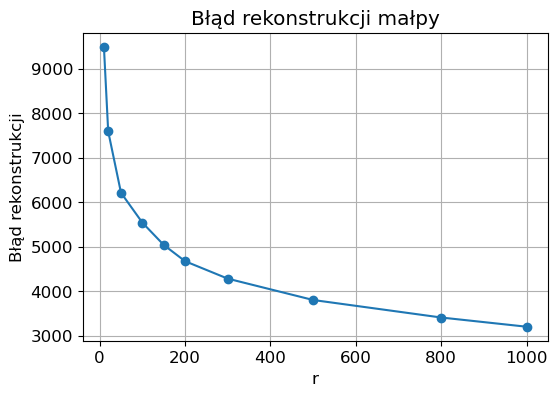

In [45]:
r_values = [10, 20, 50, 100, 150, 200, 300, 500, 800, 1000]
errors = []

for r in r_values:
    Ur = U[:, :r]
    monkey_proj = Ur @ (Ur.T @ monkey_vec)
    err = np.linalg.norm(monkey_vec - monkey_proj)
    errors.append(err)

plt.figure(figsize=(6,4))
plt.plot(r_values, errors, marker='o')
plt.xlabel("r")
plt.ylabel("Błąd rekonstrukcji")
plt.title("Błąd rekonstrukcji małpy")
plt.grid(True)
plt.show()

In [ ]:
## Eksperyment: przejście małpa → człowiek → małpa

Aby zaobserwować efekt, rekonstruujemy obraz małpy dla różnych wartości \( r \).

### Co obserwujemy?

Dla kolejnych wartości:

- \( r = 10, 20, 50 \)  
  → obraz przypomina twarz człowieka (silne uogólnienie)

- \( r = 100, 150, 200 \)  
  → pojawia się mieszanka cech (człowiek + małpa)

- \( r = 300, 500 \)  
  → coraz więcej cech małpy

- \( r = 800, 1000 \)  
  → obraz bardzo zbliżony do oryginału

---

### Czy istnieje dokładny próg?

Nie ma jednej konkretnej wartości \( r \), przy której następuje zmiana.  
Jest to **płynne przejście**.

---

### Interpretacja matematyczna

Rekonstrukcja obrazu:
\[
x_r = U_r U_r^T x
\]

- dla małego \( r \): duża utrata informacji → silne uproszczenie
- dla dużego \( r \): mała utrata informacji → wierna rekonstrukcja

---

### Wniosek

Efekt „małpa → człowiek → małpa” wynika z kompromisu między:
- redukcją wymiaru (małe \( r \)),
- a dokładnością rekonstrukcji (duże \( r \)).

To klasyczny przykład działania PCA/SVD jako metody kompresji danych.